# Ćwiczenia do wykładu 1 – Sygnały: parametry, rodzaje i proste przekształcenia

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Zadanie 1. Co zmienia każdy parametr sinusoidy?

wariant   T [s]   min   max   x(0)
2,3,0.00,0:  0.333   -2.0   2.0   0.00
1,3,0.00,0:  0.333   -1.0   1.0   0.00
2,6,0.00,0:  0.167   -2.0   2.0   0.00
2,3,1.57,0:  0.333   -2.0   2.0   2.00
2,3,0.00,1:  0.333   -1.0   3.0   1.00


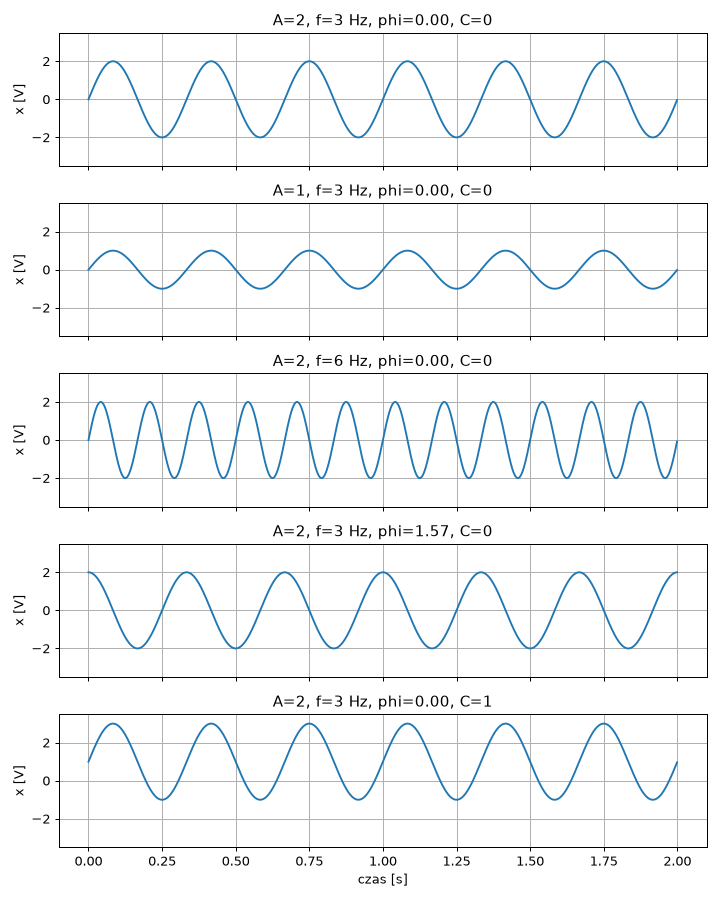

In [2]:
t = np.arange(0, 2, 0.001)               # czas od 0 do 2 s co 1 ms

def sinus(A, f, phi, C):
    return A * np.sin(2 * np.pi * f * t + phi) + C

warianty = [            # (A, f, phi, C)
    (2, 3, 0, 0),       # wariant bazowy
    (1, 3, 0, 0),       # zmieniona tylko amplituda
    (2, 6, 0, 0),       # zmieniona tylko częstotliwość
    (2, 3, np.pi/2, 0), # zmieniona tylko faza
    (2, 3, 0, 1),       # zmienione tylko przesunięcie
]

fig, osie = plt.subplots(len(warianty), 1, figsize=(8, 10), sharex=True)
for ax, (A, f, phi, C) in zip(osie, warianty):
    ax.plot(t, sinus(A, f, phi, C))
    ax.set_ylim(-3.5, 3.5)
    ax.set_title(f"A={A}, f={f} Hz, phi={phi:.2f}, C={C}")
    ax.set_ylabel("x [V]")
    ax.grid(True)
osie[-1].set_xlabel("czas [s]")
plt.tight_layout()
plt.savefig("zadanie1.png")
plt.show()

# wartości ze wzoru: T = 1/f, min = C - A, max = C + A, x(0) = A*sin(phi) + C
print("wariant   T [s]   min   max   x(0)")
for A, f, phi, C in warianty:
    print(f"{A},{f},{phi:.2f},{C}:  {1/f:.3f}  {C-A:5.1f} {C+A:5.1f}  {A*np.sin(phi)+C:5.2f}")

## Zadanie 2. Cztery podstawowe sygnały

u: [0. 1. 1. 1. 1.]
p: [0. 1. 1. 0. 0.]
r: [0.  0.  0.5 1.  2. ]
e: [0.    1.    0.368 0.135 0.018]


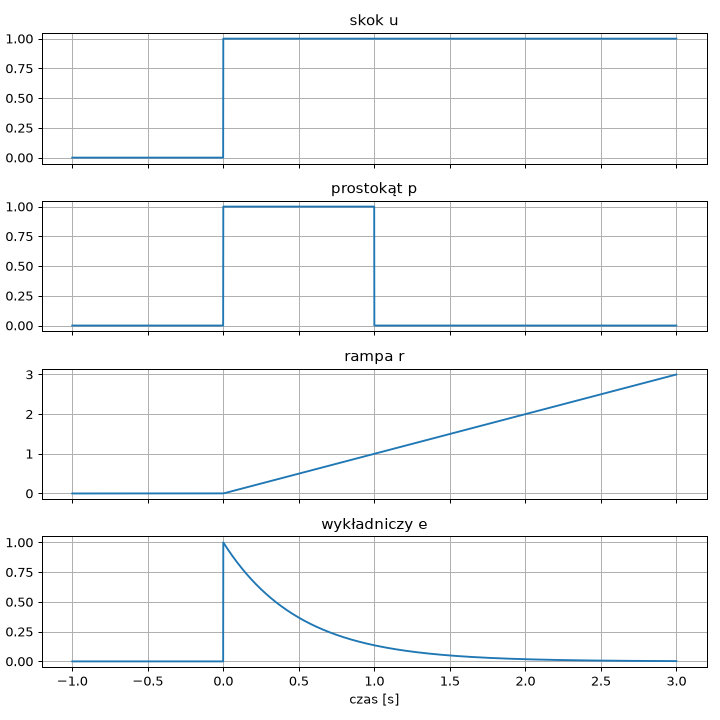

In [3]:
def u(t):   # skok: 0 przed chwilą 0, potem 1
    return np.where(t >= 0, 1.0, 0.0)

def p(t):   # impuls prostokątny: 1 dla 0 <= t < 1, poza tym 0
    return np.where((t >= 0) & (t < 1), 1.0, 0.0)

def r(t):   # rampa: 0 dla t < 0, potem rośnie jak t
    return np.maximum(t, 0)

def e(t):   # wykładniczy: exp(-2t) dla t >= 0, wcześniej 0
    return np.where(t >= 0, np.exp(-2 * t), 0.0)

t = np.arange(-1, 3, 0.001)
fig, osie = plt.subplots(4, 1, figsize=(8, 8), sharex=True)
for ax, (nazwa, s) in zip(osie, [("skok u", u), ("prostokąt p", p),
                                  ("rampa r", r), ("wykładniczy e", e)]):
    ax.plot(t, s(t))
    ax.set_title(nazwa)
    ax.grid(True)
osie[-1].set_xlabel("czas [s]")
plt.tight_layout()
plt.savefig("zadanie2.png")
plt.show()

tt = np.array([-0.5, 0, 0.5, 1, 2])
print("u:", u(tt))
print("p:", p(tt))
print("r:", r(tt))
print("e:", np.round(e(tt), 3))

## Zadanie 3. Przesunięcie, ściśnięcie i odbicie
Przewidywania (przed uruchomieniem): s(t) – szczyt 0, >0 dla (−1, 1); s(t−1) – szczyt 1, >0 dla (0, 2);
s(2t) – szczyt 0, >0 dla (−0,5; 0,5); s(−t) – szczyt 0, >0 dla (−1, 1).

s(t)      szczyt w t = -0.000,  > 0 dla -0.999 … +1.000
s(t - 1)  szczyt w t = +1.000,  > 0 dla +0.001 … +2.000
s(2t)     szczyt w t = -0.000,  > 0 dla -0.499 … +0.500
s(-t)     szczyt w t = -0.000,  > 0 dla -0.999 … +1.000


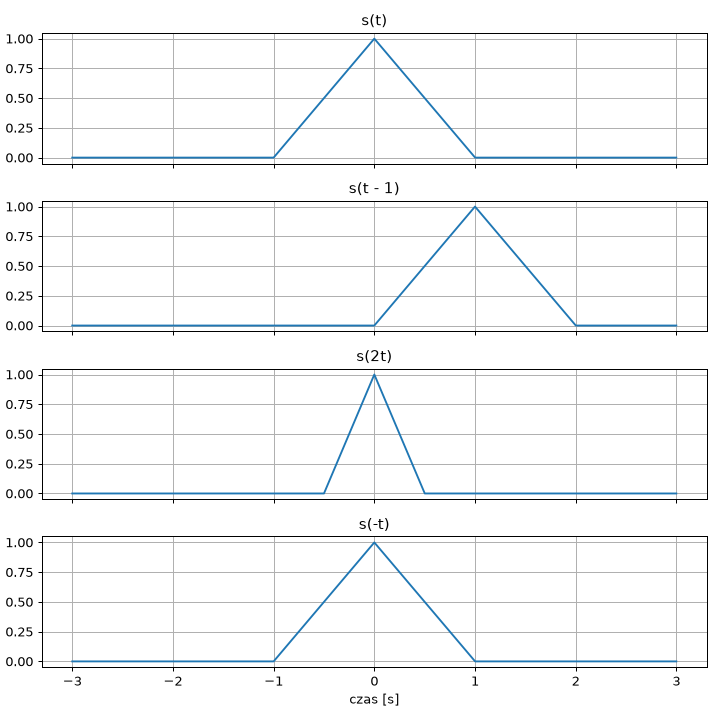

In [4]:
def s(t):    # trójkąt: szczyt 1 w chwili t = 0, podstawa od -1 do 1
    return np.maximum(1 - np.abs(t), 0)

t = np.arange(-3, 3, 0.001)
warianty = {"s(t)": s(t), "s(t - 1)": s(t - 1), "s(2t)": s(2 * t), "s(-t)": s(-t)}

fig, osie = plt.subplots(4, 1, figsize=(8, 8), sharex=True, sharey=True)
for ax, (nazwa, y) in zip(osie, warianty.items()):
    ax.plot(t, y)
    ax.set_title(nazwa)
    ax.grid(True)
osie[-1].set_xlabel("czas [s]")
plt.tight_layout()
plt.savefig("zadanie3.png")
plt.show()

for nazwa, y in warianty.items():
    dodatnie = t[y > 0]
    print(f"{nazwa:9s} szczyt w t = {t[np.argmax(y)]:+.3f},  > 0 dla {dodatnie[0]:+.3f} … {dodatnie[-1]:+.3f}")

## Zadanie 4. Z czego składa się pomiar?

p(t+0,5) = p(t): True
x(t+0,5) = x(t): False


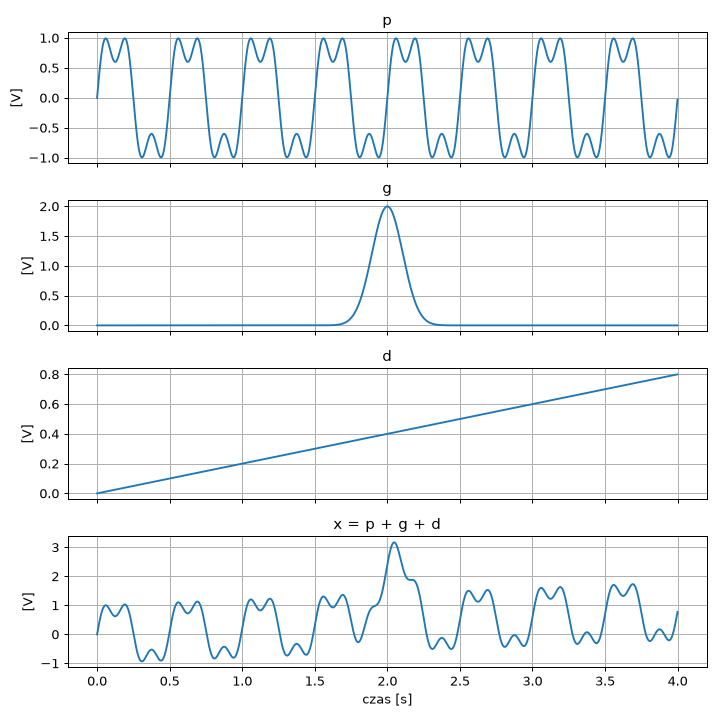

In [5]:
t = np.arange(0, 4, 0.001)
p = np.sin(2*np.pi*2*t) + 0.4*np.sin(2*np.pi*6*t)   # część okresowa
g = 2 * np.exp(-((t - 2) / 0.15)**2)                 # krótkie zdarzenie
d = 0.2 * t                                          # powolny wzrost
x = p + g + d                                        # suma wszystkich trzech składowych

fig, osie = plt.subplots(4, 1, figsize=(8, 8), sharex=True)
for ax, (nazwa, y) in zip(osie, [("p", p), ("g", g), ("d", d), ("x = p + g + d", x)]):
    ax.plot(t, y)
    ax.set_title(nazwa)
    ax.set_ylabel("[V]")
    ax.grid(True)
osie[-1].set_xlabel("czas [s]")
plt.tight_layout()
plt.savefig("zadanie4.png")
plt.show()

# sprawdzenie okresu p: przesunięcie o 0,5 s (500 próbek) nie zmienia p
print("p(t+0,5) = p(t):", np.allclose(p[500:], p[:-500]))
print("x(t+0,5) = x(t):", np.allclose(x[500:], x[:-500]))

## Zadanie 5. Czas ciągły i czas dyskretny
Rysunek wykonany w Pythonie zamiast na kartce (te same zasady: pełne kółko – wartość należy do przedziału).

x(0) = 2  x(1) = -1  z[0] = 2  z[3] = 0


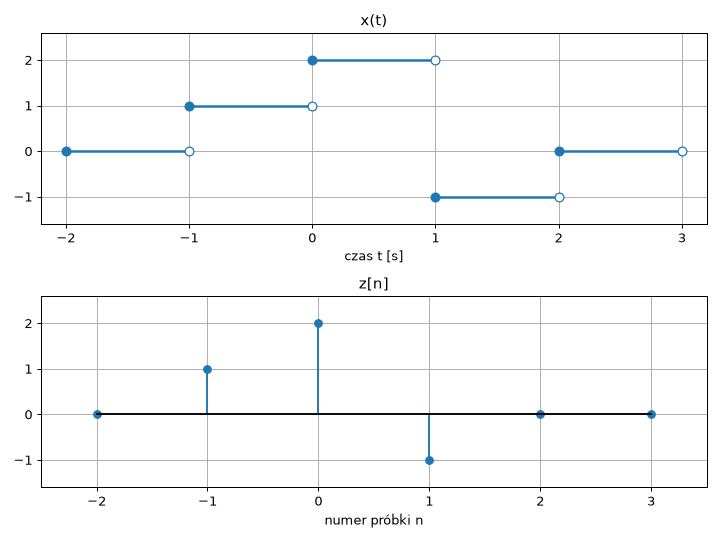

In [6]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(8, 6))
odcinki = [(-2, -1, 0), (-1, 0, 1), (0, 1, 2), (1, 2, -1), (2, 3, 0)]
for t0, t1, v in odcinki:
    a1.plot([t0, t1], [v, v], "C0", lw=2)
    a1.plot(t0, v, "o", color="C0", ms=7)                      # początek należy do przedziału
    a1.plot(t1, v, "o", mfc="white", mec="C0", ms=7)            # koniec nie należy
a1.set_xlim(-2.2, 3.2); a1.set_ylim(-1.6, 2.6); a1.grid(True)
a1.set_title("x(t)"); a1.set_xlabel("czas t [s]")

n = np.arange(-2, 4)
z = np.array([0, 1, 2, -1, 0, 0])
a2.stem(n, z, basefmt="k-")
a2.set_xlim(-2.5, 3.5); a2.set_ylim(-1.6, 2.6); a2.grid(True)
a2.set_title("z[n]"); a2.set_xlabel("numer próbki n")
plt.tight_layout()
plt.savefig("zadanie5.png")
plt.show()

def x5(t):
    return np.select([(t >= -1) & (t < 0), (t >= 0) & (t < 1), (t >= 1) & (t < 2)], [1, 2, -1], 0)
print("x(0) =", x5(np.array(0.0)), " x(1) =", x5(np.array(1.0)), " z[0] =", z[n == 0][0], " z[3] =", z[n == 3][0])

## Zadanie 6 (dla chętnych). Szum i powtarzalne losowanie

średnia = -0.0087  odchylenie = 0.2966
ziarno 42: True  ziarno 43: False


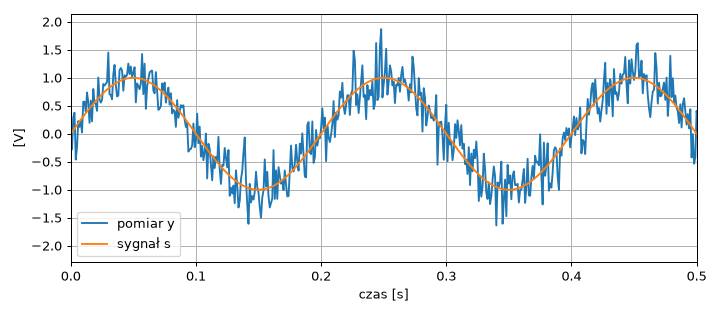

In [7]:
t = np.arange(1000) / 1000
s = np.sin(2 * np.pi * 5 * t)              # sygnał
rng = np.random.default_rng(42)            # generator liczb losowych z ziarnem 42
n = rng.normal(0, 0.3, 1000)               # szum: średnia 0, odchylenie 0,3
y = s + n                                  # pomiar = sygnał + szum

plt.figure(figsize=(8, 3.5))
plt.plot(t, y, label="pomiar y")
plt.plot(t, s, label="sygnał s")
plt.xlim(0, 0.5); plt.xlabel("czas [s]"); plt.ylabel("[V]"); plt.legend(); plt.grid(True)
plt.tight_layout(); plt.savefig("zadanie6.png"); plt.show()

print("średnia =", round(np.mean(n), 4), " odchylenie =", round(np.std(n), 4))
n2 = np.random.default_rng(42).normal(0, 0.3, 1000)
n3 = np.random.default_rng(43).normal(0, 0.3, 1000)
print("ziarno 42:", np.array_equal(n, n2), " ziarno 43:", np.array_equal(n, n3))

## Zadanie 7 (dla chętnych). Czy suma dwóch sinusoid zawsze jest okresowa?

0.5 1.0000000000000075 0.7956931896415836
1 1.6209256159527285e-14 0.963902518402848
2 1.9984014443252818e-14 0.5132883894638656


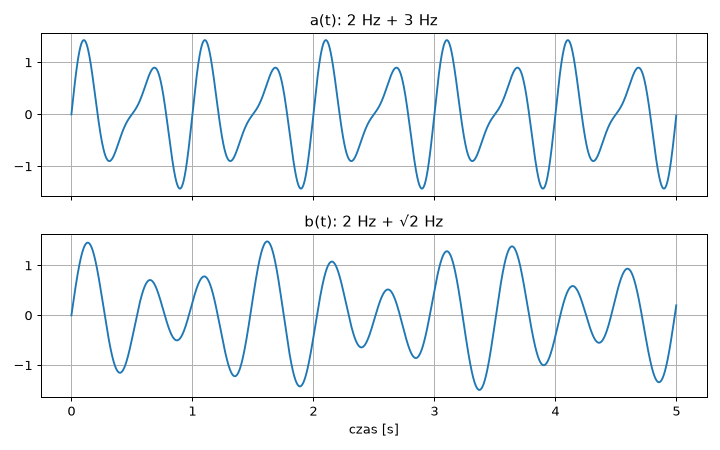

In [8]:
def a(t):
    return np.sin(2*np.pi*2*t) + 0.5*np.sin(2*np.pi*3*t)

def b(t):
    return np.sin(2*np.pi*2*t) + 0.5*np.sin(2*np.pi*np.sqrt(2)*t)

t = np.arange(0, 5, 0.001)
for T in [0.5, 1, 2]:
    print(T, np.max(np.abs(a(t + T) - a(t))), np.max(np.abs(b(t + T) - b(t))))

fig, (a1, a2) = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
a1.plot(t, a(t)); a1.set_title("a(t): 2 Hz + 3 Hz"); a1.grid(True)
a2.plot(t, b(t)); a2.set_title("b(t): 2 Hz + √2 Hz"); a2.grid(True)
a2.set_xlabel("czas [s]")
plt.tight_layout(); plt.savefig("zadanie7.png"); plt.show()

## Zadanie 8 (dla chętnych). Czy średnia i RMS wystarczą do opisu sygnału?

x: średnia = 0.0000, RMS = 0.7071
2x: średnia = 0.0000, RMS = 1.4142
y: średnia = -0.0000, RMS = 0.7071


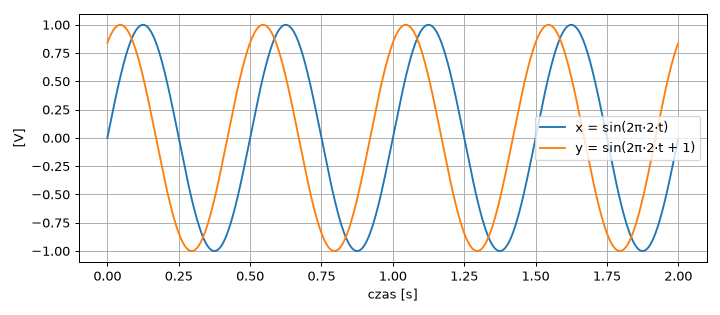

In [9]:
t = np.arange(0, 2, 0.001)
x = np.sin(2 * np.pi * 2 * t)

def srednia(v):
    return np.mean(v)

def rms(v):
    return np.sqrt(np.mean(v**2))

y = np.sin(2 * np.pi * 2 * t + 1)          # inny sygnał o tej samej średniej i RMS
for nazwa, v in [("x", x), ("2x", 2 * x), ("y", y)]:
    print(f"{nazwa}: średnia = {srednia(v):.4f}, RMS = {rms(v):.4f}")

plt.figure(figsize=(8, 3.5))
plt.plot(t, x, label="x = sin(2π·2·t)")
plt.plot(t, y, label="y = sin(2π·2·t + 1)")
plt.xlabel("czas [s]"); plt.ylabel("[V]"); plt.legend(); plt.grid(True)
plt.tight_layout(); plt.savefig("zadanie8.png"); plt.show()